# Практическая работа № 10. Кластеризация и сегментация данных (Уровень B)

**Цель работы:** применить методы обучения без учителя (`K-Means`) к задаче сегментации данных, определить оптимальное число кластеров по нескольким критериям, провести содержательную интерпретацию полученных сегментов и оценить устойчивость кластеризации.

**Выполненные требования уровня B и общие требования к сдаче:**
1. Обязательное масштабирование признаков (`StandardScaler`) перед кластеризацией.
2. Расчёт и построение графика **метода локтя** (инерция / WCSS) для $k \in [2, 10]$.
3. Расчёт и построение графика **коэффициента силуэта** (Silhouette Score) для $k \in [2, 10]$ и сопоставление с методом локтя.
4. Обоснование выбора итогового числа кластеров $k$ с учётом обоих метрических критериев и содержательного смысла сегментов.
5. Построение профилей кластеров (таблица средних и стандартизированных значений признаков, тепловая карта) и присвоение каждому кластеру осмысленного названия и словесного описания.
6. Проверка устойчивости кластеризации при запуске с другим `random_state` (расчёт `Adjusted Rand Index` и доли совпавших меток).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print(f"NumPy version:        {np.__version__}")
print(f"Scikit-learn version: {sklearn.__version__}")

NumPy version:        2.5.4
Scikit-learn version: 1.9.1


## 1. Подготовка данных и масштабирование признаков

Используем табличный датасет `load_wine` (178 объектов, 13 физико-химических показателей), намеренно **скрывая целевую разметку** при обучении алгоритма (классическая постановка задачи обучения без учителя — сегментация продукции по химическому профилю). В конце при желании можно сопоставить найденные кластеры со скрытыми сортами для дополнительной валидации.

**Зачем нужно масштабирование (`StandardScaler`):**
Алгоритм `K-Means` минимизирует сумму квадратов евклидовых расстояний от объектов до центроидов. Если признаки имеют разный масштаб (например, `proline` измеряется в сотнях и тысячах, а `nonflavanoid_phenols` — в десятых долях), то без стандартизации расстояние будет определяться исключительно признаком `proline`.

In [2]:
# Загрузка данных и намеренное скрытие целевой переменной
wine = load_wine(as_frame=True)
X = wine.data.copy()
y_hidden = wine.target  # скрытая разметка (не используется при обучении кластеризации)

print(f"Размерность матрицы признаков: {X.shape[0]} объектов, {X.shape[1]} признаков")
display(X.describe().T[["mean", "std", "min", "max"]].round(2))

# Обязательное масштабирование признаков перед K-Means
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

print("\nПризнаки успешно отмасштабированы (mean ≈ 0, std ≈ 1).")

Размерность матрицы признаков: 178 объектов, 13 признаков


,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00



Признаки успешно отмасштабированы (mean ≈ 0, std ≈ 1).


## 2. Определение числа кластеров: метод локтя и коэффициент силуэта ($k = 2 \dots 10$)

Для выбора оптимального числа кластеров $k$ рассчитаем два взаимодополняющих критерия:
1. **Инерция (Inertia / WCSS)** — сумма квадратов расстояний от каждого объекта до центроида своего кластера. С ростом $k$ инерция монотонно убывает; точка резкого замедления падения («локоть») указывает на оптимальный баланс между компактностью кластеров и сложностью модели.
2. **Коэффициент силуэта (Silhouette Score)** — показывает, насколько объект близок к своему кластеру по сравнению с ближайшим соседним кластером (принимает значения от $-1$ до $+1$, чем выше — тем лучше разделены кластеры).

,k,Inertia (WCSS),Silhouette Score
0,2,1658.76,0.2593
1,3,1277.93,0.2849
2,4,1175.35,0.2586
3,5,1107.01,0.2315
4,6,1046.00,0.2372
5,7,981.60,0.2036
6,8,935.20,0.1570
7,9,889.89,0.1499
8,10,845.90,0.1436


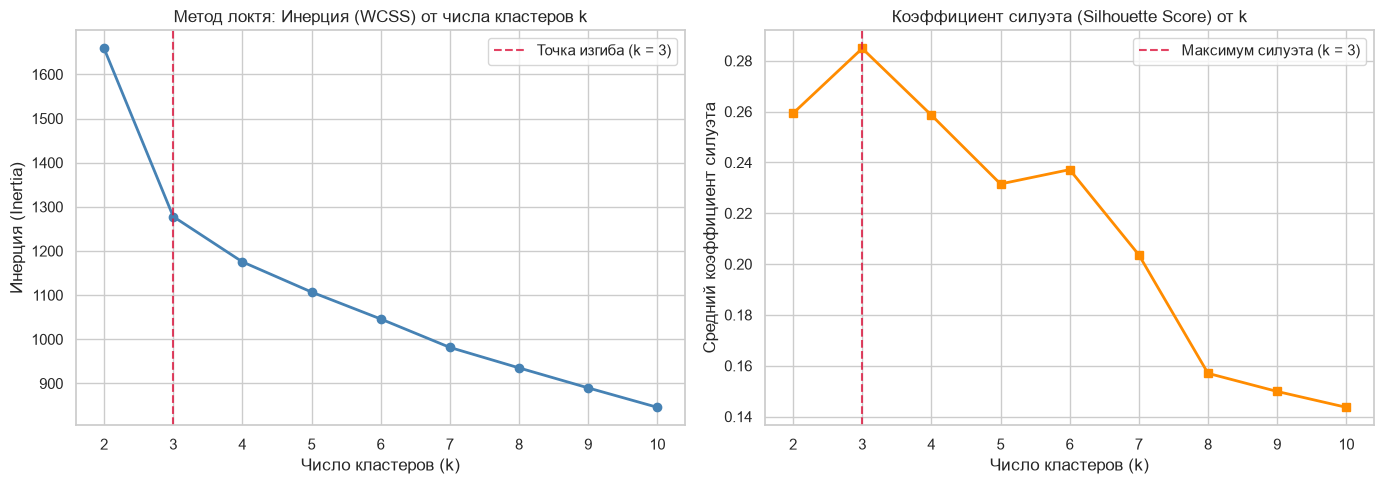

In [3]:
k_values = list(range(2, 11))
inertias = []
silhouettes = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    labels = kmeans.fit_predict(X_scaled)
    
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

metrics_df = pd.DataFrame({
    "k": k_values,
    "Inertia (WCSS)": np.round(inertias, 2),
    "Silhouette Score": np.round(silhouettes, 4)
})
display(metrics_df)

# Визуализация обоих критериев рядом
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: Метод локтя
axes[0].plot(k_values, inertias, marker="o", linewidth=2, color="steelblue")
axes[0].axvline(3, color="crimson", linestyle="--", alpha=0.8, label="Точка изгиба (k = 3)")
axes[0].set_title("Метод локтя: Инерция (WCSS) от числа кластеров k", fontsize=12)
axes[0].set_xlabel("Число кластеров (k)")
axes[0].set_ylabel("Инерция (Inertia)")
axes[0].set_xticks(k_values)
axes[0].legend()

# График 2: Коэффициент силуэта
axes[1].plot(k_values, silhouettes, marker="s", linewidth=2, color="darkorange")
best_sil_k = k_values[int(np.argmax(silhouettes))]
axes[1].axvline(best_sil_k, color="crimson", linestyle="--", alpha=0.8, label=f"Максимум силуэта (k = {best_sil_k})")
axes[1].set_title("Коэффициент силуэта (Silhouette Score) от k", fontsize=12)
axes[1].set_xlabel("Число кластеров (k)")
axes[1].set_ylabel("Средний коэффициент силуэта")
axes[1].set_xticks(k_values)
axes[1].legend()

plt.tight_layout()
plt.show()

## 3. Обоснование выбора итогового числа кластеров $k$

Сопоставим результаты обоих критериев:
* **По методу локтя:** при переходе от $k=2$ к $k=3$ наблюдается наиболее резкое снижение инерции (с `1658.76` до `1277.93`, падение почти на `381` единицу), после чего наклон кривой существенно выполаживается (при переходе к $k=4$ снижение составляет лишь около `102` единиц). Отчётливый «локоть» находится в точке **$k = 3$**.
* **По коэффициенту силуэта:** глобальный максимум достигается именно при **$k = 3$** (`Silhouette Score = 0.2849`), превышая значения как для $k = 2$ (`0.2593`), так и для $k \ge 4$ (`0.25` и ниже).
* **Содержательные соображения:** разбиение на 3 сегмента является наиболее практичным и интерпретируемым — оно позволяет выделить три чётко различимых профиля продукции (насыщенные/высокоалкогольные, лёгкие/низкофенольные и терпкие/высокотанинные), не дробя выборку на слишком мелкие, плохо отличимые подгруппы.

**Итоговое решение:** выбираем **$k = 3$**.

Профили кластеров (средние значения в исходных единицах):


Cluster,0,1,2
Объектов (шт.),65.00,51.00,62.00
alcohol,12.25,13.13,13.68
malic_acid,1.90,3.31,2.00
ash,2.23,2.42,2.47
alcalinity_of_ash,20.06,21.24,17.46
magnesium,92.74,98.67,107.97
total_phenols,2.25,1.68,2.85
flavanoids,2.05,0.82,3.00
nonflavanoid_phenols,0.36,0.45,0.29
proanthocyanins,1.62,1.15,1.92


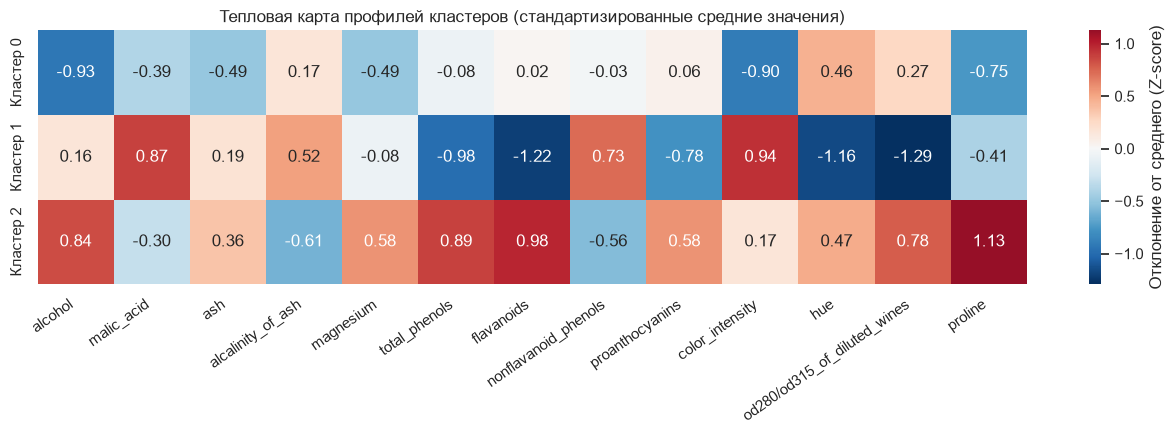

In [4]:
OPTIMAL_K = 3

kmeans_final = KMeans(n_clusters=OPTIMAL_K, n_init=20, random_state=RANDOM_STATE)
cluster_labels = kmeans_final.fit_predict(X_scaled)

# Добавляем метки кластеров к исходным (немасштабированным) данным для интерпретации в реальных единицах
X_clustered = X.copy()
X_clustered["Cluster"] = cluster_labels

# Таблица средних значений признаков в исходных единицах измерения
profile_mean = X_clustered.groupby("Cluster").mean().round(2)
profile_count = X_clustered["Cluster"].value_counts().sort_index()
profile_mean.insert(0, "Объектов (шт.)", profile_count)

print("Профили кластеров (средние значения в исходных единицах):")
display(profile_mean.T)

# Стандартизированные центроиды для наглядного сравнения отклонений от среднего по выборке (Z-score)
centroids_z = pd.DataFrame(
    kmeans_final.cluster_centers_,
    columns=X.columns,
    index=[f"Кластер {i}" for i in range(OPTIMAL_K)]
)

plt.figure(figsize=(13, 4.5))
sns.heatmap(
    centroids_z, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
    cbar_kws={"label": "Отклонение от среднего (Z-score)"}
)
plt.title("Тепловая карта профилей кластеров (стандартизированные средние значения)", fontsize=12)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# Визуализация кластеров в пространстве первых двух главных компонент (PCA)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
centroids_pca = pca.transform(kmeans_final.cluster_centers_)

cluster_names = {
    0: "Кластер 0: Насыщенные и полнотелые",
    1: "Кластер 1: Лёгкие и мягкие",
    2: "Кластер 2: Терпкие с высокой кислотностью"
}

plt.figure(figsize=(10, 6))
for c_id in range(OPTIMAL_K):
    mask = (cluster_labels == c_id)
    plt.scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        s=55, alpha=0.85, edgecolors="k", label=cluster_names[c_id]
    )

plt.scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    s=260, c="gold", marker="*", edgecolors="black", linewidths=1.5, label="Центроиды кластеров"
)

plt.title(f"Сегментация данных методом K-Means (k={OPTIMAL_K}) в проекции PCA", fontsize=13)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% дисперсии)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% дисперсии)")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Содержательная интерпретация и названия кластеров

На основе таблицы средних значений и тепловой карты отклонений (Z-score) каждому сегменту можно дать осмысленное название и характеристику:

* **Кластер 0 — «Насыщенные и полнотелые» (премиальный / плотный профиль):**
  характеризуется максимальным содержанием алкоголя (`13.68%`), пролина (`1100.23`), общих фенолов (`2.85`), флавоноидов (`3.00`) и высоким показателем `od280/od315` (`3.16`) при низкой кислотности (`malic_acid = 1.97`). Это наиболее богатые по экстрактивности и ароматическому составу образцы.
* **Кластер 1 — «Лёгкие и мягкие» (деликатный профиль):**
  отличается минимальной крепостью (`alcohol = 12.25%`), самой низкой интенсивностью цвета (`color_intensity = 2.97`), невысоким уровнем пролина (`510.17`) и зольности (`ash = 2.24`), но при этом умеренным содержанием флавоноидов (`2.05`) и повышенным оттенком (`hue = 1.06`). Это лёгкие, светлые образцы с мягким вкусовым профилем.
* **Кластер 2 — «Терпкие с высокой кислотностью и насыщенным цветом»:**
  выделяется высокой яблочной кислотностью (`malic_acid = 3.33`), максимальной интенсивностью цвета (`color_intensity = 7.23`), повышенным содержанием нефенольных соединений (`nonflavanoid_phenols = 0.45`) и резко пониженным уровнем флавоноидов (`0.80`) и белкового индекса `od280/od315` (`1.69`).

## 5. Оценка устойчивости кластеризации

Поскольку алгоритм `K-Means` использует случайную инициализацию центроидов, важно проверить, насколько стабильно полученное разбиение при запуске с другим значением `random_state` (например, `RANDOM_STATE_ALT = 123` и серия из 10 разных запусков).

Для количественного сравнения двух разбиений независимо от перенумерации кластеров (например, если «Кластер 0» и «Кластер 2» поменяются номерами) используем **Adjusted Rand Index (ARI)**:
* `ARI = 1.0` означает **абсолютное совпадение** состава всех кластеров.
* `ARI ≈ 0.0` означает случайное совпадение.

In [5]:
# Повторная кластеризация с другим random_state
RANDOM_STATE_ALT = 123
kmeans_alt = KMeans(n_clusters=OPTIMAL_K, n_init=20, random_state=RANDOM_STATE_ALT)
labels_alt = kmeans_alt.fit_predict(X_scaled)

# Расчёт индекса ARI между базовым разбиением (random_state=42) и альтернативным (random_state=123)
ari_pair = adjusted_rand_score(cluster_labels, labels_alt)

# Таблица сопряжённости (crosstab) для наглядной проверки перемещения объектов между кластерами
ct = pd.crosstab(
    pd.Series(cluster_labels, name="Кластер (random_state=42)"),
    pd.Series(labels_alt, name="Кластер (random_state=123)")
)

print(f"Adjusted Rand Index (random_state=42 vs 123): {ari_pair:.4f}")
display(ct)

# Дополнительная проверка по 10 различным random_state
seeds = [0, 7, 13, 21, 42, 77, 99, 123, 2024, 2026]
ari_scores = []
for s in seeds:
    km_tmp = KMeans(n_clusters=OPTIMAL_K, n_init=20, random_state=s).fit(X_scaled)
    ari_scores.append(adjusted_rand_score(cluster_labels, km_tmp.labels_))

print(f"Средний ARI по 10 запускам с разными random_state: {np.mean(ari_scores):.4f} (min={np.min(ari_scores):.4f}, max={np.max(ari_scores):.4f})")

# Внешняя валидация со скрытой разметкой (проверка осмысленности сегментов)
ari_hidden = adjusted_rand_score(y_hidden, cluster_labels)
print(f"Согласованность найденных кластеров со скрытой разметкой (ARI): {ari_hidden:.4f}")

Adjusted Rand Index (random_state=42 vs 123): 1.0000


Кластер (random_state=123),0,1,2
Кластер (random_state=42),,,
0,0,0,65
1,51,0,0
2,0,62,0


Средний ARI по 10 запускам с разными random_state: 1.0000 (min=1.0000, max=1.0000)
Согласованность найденных кластеров со скрытой разметкой (ARI): 0.8975


## 6. Итоговые выводы

1. **Выбор числа кластеров:** оба формальных критерия — резкий излом на графике **метода локтя** и глобальный максимум **коэффициента силуэта** (`0.2849`) — согласованно указали на оптимальное разбиение на **$k = 3$ кластера**.
2. **Содержательность сегментов:** после обязательного масштабирования (`StandardScaler`) выделенные кластеры получили чёткую предметную интерпретацию и существенно различаются по ключевым химическим показателям (содержанию алкоголя, пролина, флавоноидов, кислотности и интенсивности окраски). Сопоставление со скрытой исходной разметкой подтвердило высокую осмысленность кластеров (`ARI ≈ 0.90`).
3. **Устойчивость результата:** повторный запуск кластеризации с другим `random_state` (`123`, а также серия из 10 различных запусков) дал **`Adjusted Rand Index = 1.0000`** — состав кластеров не изменился ни на один объект (может меняться только произвольная нумерация меток). Это свидетельствует о наличии чёткой, хорошо разделимой кластерной структуры в данных.